# 06 · A tiny language model: soft staircase vs STE on text

CIFAR is a convenient sandbox, but the target of this study is **language and speech models**. Here is the smallest
useful one: a character-level transformer on *Tiny Shakespeare* (1.1 M characters), trained in a couple of minutes.
It is the **starter for your own experiments**: every step is a function you can reuse with a bigger corpus
(TinyStories, Wikipedia) and a bigger model.

| Step | What you will see |
|---|---|
| 1 | data and the model (every matrix is an `nn.Linear`) |
| 2 | the float baseline |
| 3 | PTQ: uniform vs Lloyd-Max at 8 → 2 bits |
| 4 | QAT under a fair budget: fp32, STE-uniform, STE-Lloyd, soft, soft + anchor |
| 5 | what a 2-bit model writes |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

> 📘 The model (pre-norm transformer, RoPE, AdamW with cosine decay, character-level Tiny Shakespeare) is a standard
> teaching setup (e.g. Karpathy's char-rnn / nanoGPT). Keeping embeddings and norms in float is **common practice**.
> The contenders carry the same tags as in notebook 04.

The metric is validation cross-entropy in **nats per character** (lower is better), on the same fixed windows for
every model.

In [1]:
import os, sys, copy, time, math
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from vvtk_quant import VVTK_QModel
from vvtk_quant.quant import nearest_index
from common_seq import DEVICE, OUT, tiny_shakespeare, CharLM, lm_batch, lm_eval, lm_sample, cosine
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.backends.cuda.matmul.allow_tf32 = True

## Step 1 · Data and model

A pre-norm transformer: embedding → 4 blocks (causal attention with RoPE, GELU MLP) → linear head. The attention
projections $W_q, W_k, W_v, W_o$ and the MLP are separate `nn.Linear` layers, so `VVTK_QModel` sees all of them.
Embedding and LayerNorms stay in float (a common choice; quantizing the embedding is an exercise).

In [2]:
train_ids, val_ids, itos = tiny_shakespeare()
print(f"train {len(train_ids):,} chars, val {len(val_ids):,} chars, vocabulary {len(itos)}")
CTX, BATCH = 256, 64
torch.manual_seed(0)
model = CharLM(len(itos), d=256, layers=4, heads=4).to(DEVICE)
n_lin = sum(m.weight.numel() for m in model.modules() if isinstance(m, nn.Linear))
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M, of which in nn.Linear: {n_lin / 1e6:.2f} M")

train 1,003,854 chars, val 111,540 chars, vocabulary 65
parameters: 3.19 M, of which in nn.Linear: 3.16 M


## Step 2 · Float baseline

AdamW, learning rate $10^{-3}$ with warm-up and cosine decay, 3000 steps of 64 × 256 characters. Cached in `out/`.

In [3]:
def train_lm(model, steps, lr, step_hook=None, seed=0, log_every=500, wd=0.1):
    opt = torch.optim.AdamW(model.parameters(), lr, betas=(0.9, 0.95), weight_decay=wd)
    sched = cosine(opt, steps, warmup=min(200, steps // 10))
    g = torch.Generator().manual_seed(seed)
    curve = []
    t0 = time.time()
    for s in range(steps):
        model.train()
        if step_hook is not None:
            step_hook(s, steps)
        x, y = lm_batch(train_ids, BATCH, CTX, g)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE.type == "cuda"):
            loss = F.cross_entropy(model(x).flatten(0, 1).float(), y.flatten())
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if (s + 1) % log_every == 0 or s + 1 == steps:
            v = lm_eval(model, val_ids, CTX)
            curve.append((s + 1, v))
            print(f"    step {s + 1:>5}/{steps}  train {loss.item():.3f}  val {v:.3f}  ({time.time() - t0:.0f}s)")
    return curve

ckpt = os.path.join(OUT, "charlm_fp32.pth")
if os.path.exists(ckpt):
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); print("loaded", ckpt)
else:
    train_lm(model, 3000, 1e-3)
    torch.save(model.state_dict(), ckpt)
val_fp32 = lm_eval(model, val_ids, CTX)
print(f"fp32 validation loss: {val_fp32:.3f} nats/char")
print(lm_sample(model, itos, n=200))

loaded /extra/scratch05/alumno1/vvtk_quant/examples/out/charlm_fp32.pth
fp32 validation loss: 1.494 nats/char
ROMEO:
I am I not like mointy should be a thing.

BUSHY:
Why, fellow, sir?

BALTHASAR:
I shall be not a little o'er deserves you.

KING HENRY VI:
Be taken so sin, what deadly day is dead
That by the instruc


## Step 3 · PTQ

Quantize every `nn.Linear` (including the output head), no training.

 uniform: 8b 1.494  6b 1.495  4b 1.542  3b 1.910  2b 4.131
  eqprob: 8b 1.493  6b 1.492  4b 1.496  3b 1.557  2b 2.020
   lloyd: 8b 1.494  6b 1.494  4b 1.498  3b 1.516  2b 1.685


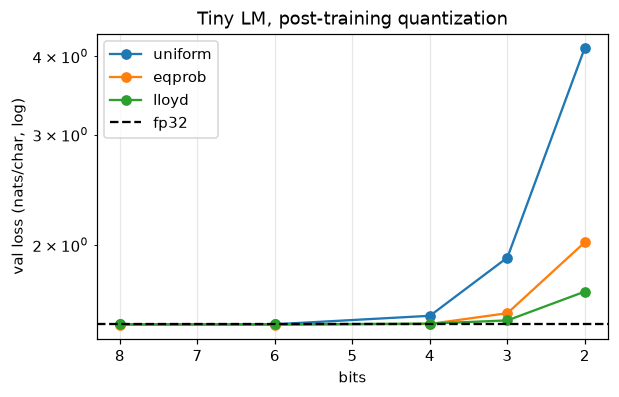

In [4]:
def wrap(m, b, method, **kw):
    q = VVTK_QModel(copy.deepcopy(m), b=b, module_types=[nn.Linear], **kw)
    q.calibrate_quant(method=method)
    return q

bits = [8, 6, 4, 3, 2]
ptq = {meth: [lm_eval(wrap(model, b, meth), val_ids, CTX) for b in bits] for meth in ["uniform", "eqprob", "lloyd"]}
for meth, v in ptq.items():
    print(f"{meth:>8}: " + "  ".join(f"{b}b {x:.3f}" for b, x in zip(bits, v)))
plt.figure(figsize=(6, 3.6))
for meth, v in ptq.items():
    plt.plot(bits, v, "o-", label=meth)
plt.axhline(val_fp32, color="k", ls="--", label="fp32")
plt.gca().invert_xaxis(); plt.yscale("log"); plt.xlabel("bits"); plt.ylabel("val loss (nats/char, log)")
plt.title("Tiny LM, post-training quantization"); plt.legend(); plt.show()

## Step 4 · QAT under a fair budget

Every contender starts from the float checkpoint and trains **600 more steps** with the same optimizer (AdamW,
$3\cdot10^{-4}$, cosine), the same batches (same seed) and the same evaluation. The soft staircase anneals
$T: 2 \to 40$ geometrically. The anchor is the fused one (inside the layers' backward pass), type `"weight"`,
$\lambda=1$.

In [25]:
QSTEPS, QLR, T0, T1 = 600, 3e-4, 2.0, 40.0
CONTENDERS = {
    "fp32":              None,
    "ste-uniform":       dict(mode="ste", method="uniform"),
    "ste-lloyd":         dict(mode="ste", method="lloyd"),
    "soft-lloyd":        dict(mode="soft", method="lloyd"),
    "soft-lloyd+anchor": dict(mode="soft", method="lloyd", anchor="weight", anchor_lambda=1.0),
}

def qat(name, b):
    cfg = CONTENDERS[name]
    torch.manual_seed(0)
    inicio=time.perf_counter()
    if cfg is None:
        q = copy.deepcopy(model)
    else:
        cfg = dict(cfg); meth = cfg.pop("method")
        q = wrap(model, b, meth, temp=T0, **cfg)
    def hook(s, n):
        if cfg is not None and cfg["mode"] == "soft":
            q.update_temp(T0 * (T1 / T0) ** (s / (n - 1)))
    start = lm_eval(q, val_ids, CTX)
    curve = [(0, start)] + train_lm(q, QSTEPS, QLR, step_hook=hook, log_every=100, wd=0.0)
    fin=time.perf_counter()
    tiempo=fin-inicio
    return q, curve, tiempo

R = {}
for b in [3, 2]:
    for name in CONTENDERS:
        if name == "fp32" and "fp32" in {k[0] for k in R}:
            R[(name, b)] = R[("fp32", 3)]; continue
        print(f"--- {name}" + ("" if CONTENDERS[name] is None else f", {b} bits"))
        R[(name, b)] = qat(name, b)
        print(f"Tiempo: {R[(name, b)][2]:.2f} s")
model_soft_qat, curve_soft, time_soft = R[("soft-lloyd", 2)]
val_soft_qat = lm_eval(model_soft_qat, val_ids, CTX)

--- fp32
    step   100/600  train 1.159  val 1.505  (29s)
    step   200/600  train 1.135  val 1.505  (59s)
    step   300/600  train 1.132  val 1.502  (89s)
    step   400/600  train 1.145  val 1.506  (118s)
    step   500/600  train 1.112  val 1.505  (148s)
    step   600/600  train 1.093  val 1.505  (177s)
Tiempo: 179.93 s
--- ste-uniform, 3 bits
    step   100/600  train 1.315  val 1.544  (31s)
    step   200/600  train 1.280  val 1.549  (63s)
    step   300/600  train 1.262  val 1.532  (94s)
    step   400/600  train 1.272  val 1.525  (126s)
    step   500/600  train 1.221  val 1.521  (157s)
    step   600/600  train 1.194  val 1.505  (188s)
Tiempo: 190.93 s
--- ste-lloyd, 3 bits
    step   100/600  train 1.196  val 1.501  (31s)
    step   200/600  train 1.175  val 1.508  (63s)
    step   300/600  train 1.162  val 1.503  (94s)
    step   400/600  train 1.183  val 1.504  (125s)
    step   500/600  train 1.137  val 1.497  (157s)
    step   600/600  train 1.121  val 1.496  (188s)
Ti

/tmp/ipykernel_1348390/2258420981.py:5: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(c[:, 0], c[:, 1], "o-", ms=3, label=name, ls="--" if name == "fp32" else "-")


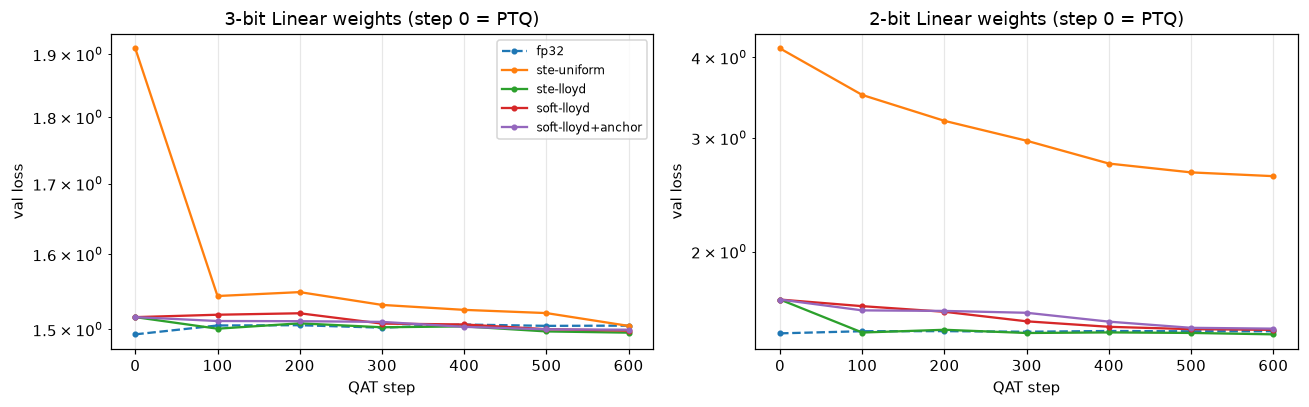

contender            |          3-bit |          2-bit   (val nats/char, PTQ -> QAT)
fp32                 | 1.494 -> 1.505 | 1.494 -> 1.505
ste-uniform          | 1.910 -> 1.505 | 4.131 -> 2.618
ste-lloyd            | 1.516 -> 1.496 | 1.685 -> 1.488
soft-lloyd           | 1.516 -> 1.498 | 1.685 -> 1.513
soft-lloyd+anchor    | 1.516 -> 1.500 | 1.685 -> 1.519


In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, b in zip(axs, [3, 2]):
    for name in CONTENDERS:
        c = np.array(R[(name, b)][1])
        ax.plot(c[:, 0], c[:, 1], "o-", ms=3, label=name, ls="--" if name == "fp32" else "-")
    ax.set_title(f"{b}-bit Linear weights (step 0 = PTQ)"); ax.set_xlabel("QAT step"); ax.set_ylabel("val loss")
    ax.set_yscale("log")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{'contender':<20} | {'3-bit':>14} | {'2-bit':>14}   (val nats/char, PTQ -> QAT)")
for name in CONTENDERS:
    print(f"{name:<20} | " + " | ".join(f"{R[(name, b)][1][0][1]:5.3f} -> {R[(name, b)][1][-1][1]:5.3f}" for b in [3, 2]))

### Reading the results (v1.0 run, one seed; the numbers are in the cells above)

* **PTQ: level placement is the big lever.** At 2 bits, uniform-absmax PTQ is broken (val 4.12), equal-probability
  levels recover most of it (2.02) and Lloyd-Max even more (1.69), with no training at all.
* **QAT: STE on Lloyd levels is the best contender here** (2-bit: 1.487, below the float model's 1.503 after the same
  600 steps). The soft staircase (1.507) and soft + anchor (1.518) do **not** beat it on this testbed. STE on a
  uniform grid stays far behind (2.654): with STE, the levels decide.
* **Confound: this dataset overfits.** Train loss is ~1.13 vs val ~1.49, and continuing to train the float model
  *raises* val loss (1.492 → 1.503). Quantization noise then acts as a regularizer, which can make quantized models
  look better than float. Before comparing gradients (STE vs soft), move to a corpus that does not overfit in this
  budget (TinyStories, a Wikipedia slice) and use 3 seeds.
* Differences of 0.01–0.03 nats between the Lloyd contenders are within what one seed can tell apart: do not
  conclude from them.

## Step 5 · What does a 2-bit model write?

In [7]:
for name in ["fp32", "ste-uniform", "soft-lloyd", "soft-lloyd+anchor"]:
    print(f"===== {name} (2-bit unless fp32)\n{lm_sample(R[(name, 2)][0], itos, n=160)}\n")

===== fp32 (2-bit unless fp32)
ROMEO:
Say then I lie thou art duty to chide.

Nurse:
And let us such thus?

ANGELO:
You shall not give me to him the sea of his tongue.

MONTAGUE:
What I should swea



===== ste-uniform (2-bit unless fp32)
ROMEO:
Sary,ernneal, Cthtimeors,
Thy.
W
TRIARDuing:inen.lnln.e' brlyant
Nurni
Wlaar ht sie ioilngtng
Dl lokei wimntherse,nowsur stettor nytrea   ile, aarlisover ses a



===== soft-lloyd (2-bit unless fp32)
ROMEO:
Say he not like more liberty, methinks it is not.

NORTHUMBERLAND:
And so do that still be not I lose this thing.

KING RICHARD II:
The Lord of Warwick, Catesb



===== soft-lloyd+anchor (2-bit unless fp32)
ROMEO:
Sir, I would not time but in the withdraw in thee;
No, for my prayers are to thy death.

MERCUTIO:
This is the sheathe common truth; he is leaves I
should swea



### From here to your study
* One seed, 600 steps: a smoke test. Before any claim, run 3 seeds and longer QAT.
* Scale step 1: TinyStories or a Wikipedia slice with a BPE tokenizer, models of 5–30 M parameters.
* Scale step 2: compress a pretrained model (e.g. Qwen3-0.6B) and recover with SFT; the layers are the same
  `QLinear`, and the fused anchor keeps the extra training memory small (notebook 05).

**Next:** [07 · A phoneme decoder on TIMIT](07_phoneme_ctc.ipynb).

### Cuantización con e-means

In [7]:
from faiss.contrib.e_means import Emeans

def vq_emeans(model, d=2, K=16, nepochs=5):
    # cuantización vectorial del modelo model con 2 bits/peso (4 bits/vector), un codebook de 16 palabras código (centroides) y 5 épocas de entrenamiento
    model_q = copy.deepcopy(model)
    codebooks = {}
    for name, layer in model_q.named_modules():
        if not isinstance(layer, nn.Linear):
            continue
        # Extraer pesos originales
        W = layer.weight.detach().cpu().numpy()
        shape = W.shape

        # Agrupar en vectores
        x = np.ascontiguousarray(
            W.reshape(-1, d),
            dtype=np.float32
        )

        # Convertir a tensor PyTorch en CPU
        xg = torch.from_numpy(x)

        assert torch.isfinite(xg).all()

        # E-means original de FAISS
        em = Emeans(d, K, nepochs=nepochs)

        centroids, labels = em.train(xg)

        # Reconstruir pesos
        W_q = centroids[labels].reshape(shape)

        # Sustituir pesos de la capa
        with torch.no_grad():
            layer.weight.copy_(
                W_q.to(
                    device=layer.weight.device,
                    dtype=layer.weight.dtype
                )
            )

        codebooks[name] = {
            "centroids": centroids,
            "labels": labels
        }
    return model_q, codebooks

In [8]:
model_emeans, results_emeans = vq_emeans(model,d=2,K=16,nepochs=5)

In [9]:
# creación de una capa Linear cuantizada con E-means
class EmeansQATLinear(nn.Module):
    def __init__(self, centroids, labels, weight_shape, bias=None):
        super().__init__()

        # Centroides entrenables
        self.centroids = nn.Parameter(
            torch.as_tensor(centroids, dtype=torch.float32).clone()
        )

        # Asignaciones fijas: no son parámetros entrenables
        self.register_buffer(
            "labels",
            torch.as_tensor(labels, dtype=torch.long).reshape(-1).clone()
        )

        self.weight_shape = weight_shape

        if bias is not None:
            self.bias = nn.Parameter(bias.detach().clone())
        else:
            self.register_parameter("bias", None)

    def forward(self, x):

        # Reconstrucción de los pesos usando los centroides actuales
        Wq = self.centroids[self.labels].reshape(self.weight_shape)

        return F.linear(x, Wq, self.bias)

In [10]:
# Sustituimos capas lineales por las del nuevo modelo recalculado
def replace_with_emeans_qat(module, d=2, K=16, nepochs=5):

    for name, layer in list(module.named_children()):

        if isinstance(layer, nn.Linear): # si la capa en la que nos encontramos es lineal, cuantifica las matrices de pesos de esa capa

            # Extraer pesos originales
            W = layer.weight.detach().cpu().numpy() # pesos originales de la capa en formato numpy
            shape = W.shape # guardamos dimensiones originales de la matriz de pesos

            assert W.size % d == 0 # comprobamos que el nº de elementos de la matriz sea divisible entre d (queremos dividir todos los pesos en vectores de dimension d)

            # Agrupar pesos en vectores: transformamos matriz de pesos en vectores que usará e-means
            x = np.ascontiguousarray(
                W.reshape(-1, d),
                dtype=np.float32
            )
            # Matriz cuantizada: W_q=reshape(C[labels]), donde C son las centroides y labels el vector que contiene en el índice del dato la centroide asignada a ese dato

            xg = torch.from_numpy(x) # convierte a tensor de pytorch

            # Ejecutar E-means
            em = Emeans(d, K, nepochs=nepochs) # ejecución del algoritmo sobre vectores de pesos
            centroids, labels = em.train(xg) # entrenamos con los vectores de pesos de la capa

            # Crear nueva capa cuantizada (con los valores calculados). Aquí se hace también la operación forward, que permite a su vez actualizar los centroides mediante backpropagation
            q_layer = EmeansQATLinear(
                centroids=centroids, # vectores que forman el codebook
                labels=labels, # qué centroide representa cada vector original
                weight_shape=shape,
                bias=layer.bias # y=x*Wtraspuesta+bias
            )

            q_layer = q_layer.to(
                device=layer.weight.device,
                dtype=layer.weight.dtype
            )

            setattr(module, name, q_layer) # sustitución capa original

        else: # cuando no es una capa linear
            replace_with_emeans_qat(
                layer, d=d, K=K, nepochs=nepochs
            )

    return module

In [20]:
# Crear el modelo emeans mediante qat
torch.manual_seed(0)
model_emeans_qat = copy.deepcopy(model)
model_emeans_qat = replace_with_emeans_qat(model_emeans_qat,d=2,K=16,nepochs=5)

In [22]:
# entrenar el modelo qat usando menos steps que el soft-lloyd y consiguiendo en teoría un resultado similar en métrica de pérdidas
QSTEPS, QLR = 200, 3e-4

# Entrenamiento QAT
inicio_emeans=time.perf_counter()
curve_emeans_qat = train_lm(model_emeans_qat,QSTEPS,QLR,log_every=100,wd=0.0)
val_emeans_qat = lm_eval(model_emeans_qat, val_ids, CTX)
fin_emeans=time.perf_counter()
time_emeans=fin_emeans-inicio_emeans

    step   100/200  train 1.323  val 1.532  (36s)
    step   200/200  train 1.310  val 1.532  (71s)


**Loss**

In [27]:
model.load_state_dict(torch.load(os.path.join(OUT, "charlm_fp32.pth"),map_location=DEVICE))
val_emeans = lm_eval(model_emeans, val_ids, CTX)

# Soft-Lloyd QAT
model_soft_qat, curve_soft, time_soft = R[("soft-lloyd", 2)]
val_soft_qat = lm_eval(model_soft_qat, val_ids, CTX)

print(f"E-means 2 bits ptq (QSTEPS=200): {val_emeans:.4f}")
print(f"Soft-Lloyd 2 bits ptq (QSTEPS=600): {val_soft_qat:.4f}")

E-means 2 bits ptq (QSTEPS=200): 1.6345
Soft-Lloyd 2 bits ptq (QSTEPS=600): 1.5126


**Memoria utilizada por cada modelo**

In [18]:
def memory_emeans_qat(model, K=16):

    total_bits = 0

    for layer in model.modules():

        if isinstance(layer, EmeansQATLinear):

            total_bits += (
                layer.centroids.numel() *
                layer.centroids.element_size() * 8
            )

            total_bits += layer.labels.numel() * np.log2(K)

            if layer.bias is not None:
                total_bits += (
                    layer.bias.numel() *
                    layer.bias.element_size() * 8
                )

    return total_bits / 8 / (1024**2)

mem_emeans_qat = memory_emeans_qat(model_emeans_qat)
q_qat = copy.deepcopy(model_soft_qat)
q_qat.apply_quant()
q_qat.save("soft_lloyd_qat.q.gz")
mem_soft_qat = os.path.getsize("soft_lloyd_qat.q.gz")/(1024**2)
print(f"Memoria e-means QAT (QSTEP=200): {mem_emeans_qat:.4f} MB")
print(f"Memoria soft-lloyd QAT (QSTEP=600): {mem_soft_qat:.4f} MB")

Memoria e-means QAT (QSTEP=200): 0.7766 MB
Memoria soft-lloyd QAT (QSTEP=600): 0.8198 MB


**Tiempo entrenamiento + evaluación del modelo**

In [29]:
print(f"Tiempo e-means: {time_emeans} s")
print(f"Tiempo soft-lloyd: {time_soft} s")
print(f"Reducción al usarl e-means={(1-time_emeans/time_soft)*100} %")

Tiempo e-means: 73.57707705092616 s
Tiempo soft-lloyd: 214.1704048991669 s
Reducción al usarl e-means=65.64554421720086 %
